#  Elastostatics Code using Quadratic Elements (ELQUABE)

A FORTRAN code for isotropic elasticity

The program allows for the traction values at both sides of the nodes connecting two elements to be different. For each particular $x_1$ or $x_2$ direction, (i) when both tractions are prescribed as different at both sides of the node the displacement is the only unknown; (ii) when the displacement and one traction is prescribed one on each side the other traction is the unknown and (iii) if only the displacement is prescribed, one value of the traction is the only unknown and this will be the same at both sides of the node.

# Mount Google Drive

# Download `quadpleh` from `Github`

In [42]:
!git clone https://github.com/e-albuquerque/BEM2D-Elastostatics-ELQUABE.git

Cloning into 'BEM2D-Elastostatics-ELQUABE'...
remote: Enumerating objects: 144, done.
remote: Counting objects: 100% (144/144), done.
remote: Compressing objects: 100% (88/88), done.
remote: Total 144 (delta 65), reused 135 (delta 56), pack-reused 0 (from 0)
Receiving objects: 100% (144/144), 4.38 MiB | 23.00 MiB/s, done.
Resolving deltas: 100% (65/65), done.


In [43]:
ls

assembly_mod.f90              eq12cb.dat     preproc.py
assembly_mod.mod              eq12cb.out     __pycache__/
assembly_mod.o                geometry.png   README.md
BEM2D-Elastostatics-ELQUABE/  input_data.py  resultado_elquabe.vtk
build.bat                     io_mod.f90     result_plot.png
data_mod.f90                  io_mod.mod     Run_elquabe_on_Colab.ipynb
data_mod.mod                  io_mod.o       solver_mod.f90
data_mod.o                    main.f90       solver_mod.mod
displacement_map.png          main.o         solver_mod.o
dpbou.dat                     Makefile       stbou.dat
dpint.dat                     placa.geo      stint.dat
elquabe.for                   placa.msh      von_mises_map.png
elquabe_modern.exe*           posproc.py


In [44]:
cd BEM2D-Elastostatics-ELQUABE/

/content/BEM2D-Elastostatics-ELQUABE/BEM2D-Elastostatics-ELQUABE/BEM2D-Elastostatics-ELQUABE


In [45]:
ls

assembly_mod.f90      geometry.png   README.md
build.bat             input_data.py  resultado_elquabe.vtk
data_mod.f90          io_mod.f90     result_plot.png
displacement_map.png  main.f90       Run_elquabe_on_Colab.ipynb
dpbou.dat             Makefile       solver_mod.f90
dpint.dat             placa.geo      stbou.dat
elquabe.for           placa.msh      stint.dat
eq12cb.dat            posproc.py     von_mises_map.png
eq12cb.out            preproc.py


# Compile the code ```elquabe.for```

In [46]:
!make

gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -c data_mod.f90
gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -c io_mod.f90
gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -c assembly_mod.f90
gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -c solver_mod.f90
gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -c main.f90
gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -o elquabe_modern.exe data_mod.o io_mod.o assembly_mod.o solver_mod.o main.o -llapack -lblas


In [47]:
ls

assembly_mod.f90      eq12cb.dat     posproc.py
assembly_mod.mod      eq12cb.out     preproc.py
assembly_mod.o        geometry.png   README.md
build.bat             input_data.py  resultado_elquabe.vtk
data_mod.f90          io_mod.f90     result_plot.png
data_mod.mod          io_mod.mod     Run_elquabe_on_Colab.ipynb
data_mod.o            io_mod.o       solver_mod.f90
displacement_map.png  main.f90       solver_mod.mod
dpbou.dat             main.o         solver_mod.o
dpint.dat             Makefile       stbou.dat
elquabe.for           placa.geo      stint.dat
elquabe_modern.exe*   placa.msh      von_mises_map.png


# Install `gmsh`

In [48]:
!apt-get update
!apt-get install gmsh
!python -m pip install gmsh

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:3 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:4 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:5 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Fetched 3,917 B in 1s (4,000 B/s)
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
gmsh is already the newest version (4.12.1+ds1-1.1build2).
0 upgraded, 0 newly installed, 0 to remove and 41 not upgraded.


# Install `meshio`

In [49]:
!pip install meshio[all]

# Gmsh geometry file (`.geo`)

In [50]:
%%writefile placa.geo
ref=.1;
L=1.;
W=1.;
Point(1) = {0, 0, 0, ref};
Point(2) = {L, 0, 0, ref};
Point(3) = {L, W, 0, ref};
Point(4) = {0, W, 0, ref};
Line(1) = {1, 2};
Line(2) = {2, 3};
Line(3) = {3, 4};
Line(4) = {4, 1};
Line Loop(1) = {1, 2, 3, 4};
Plane Surface(1) = {1};
Physical Curve("botton") = {1};
Physical Curve("right") = {2};
Physical Curve("top") = {3};
Physical Curve("left") = {4};
Physical Surface("surf1") = {1};

Overwriting placa.geo


# Generate mesh file (`.msh`) using Gmsh

In [51]:
!gmsh -2  placa.geo -o placa.msh  -order 2

Info    : Running '/usr/local/bin/gmsh -2 placa.geo -o placa.msh -order 2' [Gmsh 4.15.2, 1 node, max. 1 thread]
Info    : Started on Thu Oct 22 20:42:08 2026
Info    : Reading 'placa.geo'...
Info    : Done reading 'placa.geo'
Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : Done meshing 1D (Wall 0.000482696s, CPU 0.000402s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Plane, Frontal-Delaunay)
Info    : Done meshing 2D (Wall 0.00588789s, CPU 0.011652s)
Info    : Meshing order 2 (curvilinear on)...
Info    : [  0%] Meshing curve 1 order 2
Info    : [ 30%] Meshing curve 2 order 2
Info    : [ 50%] Meshing curve 3 order 2
Info    : [ 70%] Meshing curve 4 order 2
Info    : [ 90%] Meshing surface 1 order 2
Info    : Surface mesh: worst distortion = 1 (0 elements in ]0, 0.2]); worst gamma = 0.863919
Info    : Done meshing order 2 (Wall 0.00119

# Input data

In [52]:
%%writefile input_data.py
import numpy as np
def input_data():
    """
    Defines input parameters for the 2D Elastostatic Boundary Element Method (BEM)
    simulation using quadratic boundary elements (ELQUABE).

    Returns:
        dict: Dictionary containing:
            * title (str): Problem description title
            * bound_cond (dict): Boundary conditions for each physical edge
              (type: 0 = prescribed displacement, 1 = prescribed traction)
            * E (float): Young's modulus
            * nu (float): Poisson's ratio
            * file_name (str): Base name of the Gmsh .msh file
    """
    bound_cond = {
        'botton': {'type_x': 0, 'value_x': 0.0, 'type_y': 0, 'value_y': 0.0},
        'right':  {'type_x': 1, 'value_x': 0.0, 'type_y': 1, 'value_y': 0.0},
        'top':    {'type_x': 1, 'value_x': 0.0, 'type_y': 1, 'value_y': 1.0},
        'left':   {'type_x': 1, 'value_x': 0.0, 'type_y': 1, 'value_y': 0.0},
    }
    E = 1.0
    nu = 0.
    file_name = 'placa'
    title = 'SQUARE PLATE UNDER UNIAXIAL STATIC TRACTION (4 QUADRATIC ELEMENTS)'

    return {
        'title': title,
        'bound_cond': bound_cond,
        'E': E,
        'nu': nu,
        'file_name': file_name,
    }

Overwriting input_data.py


# Run `preproc.py`

In [53]:
!python preproc.py


Geometry plot saved to 'geometry.png'.
Input file 'eq12cb.dat' generated successfully.


# Show Geometry and boundary conditions

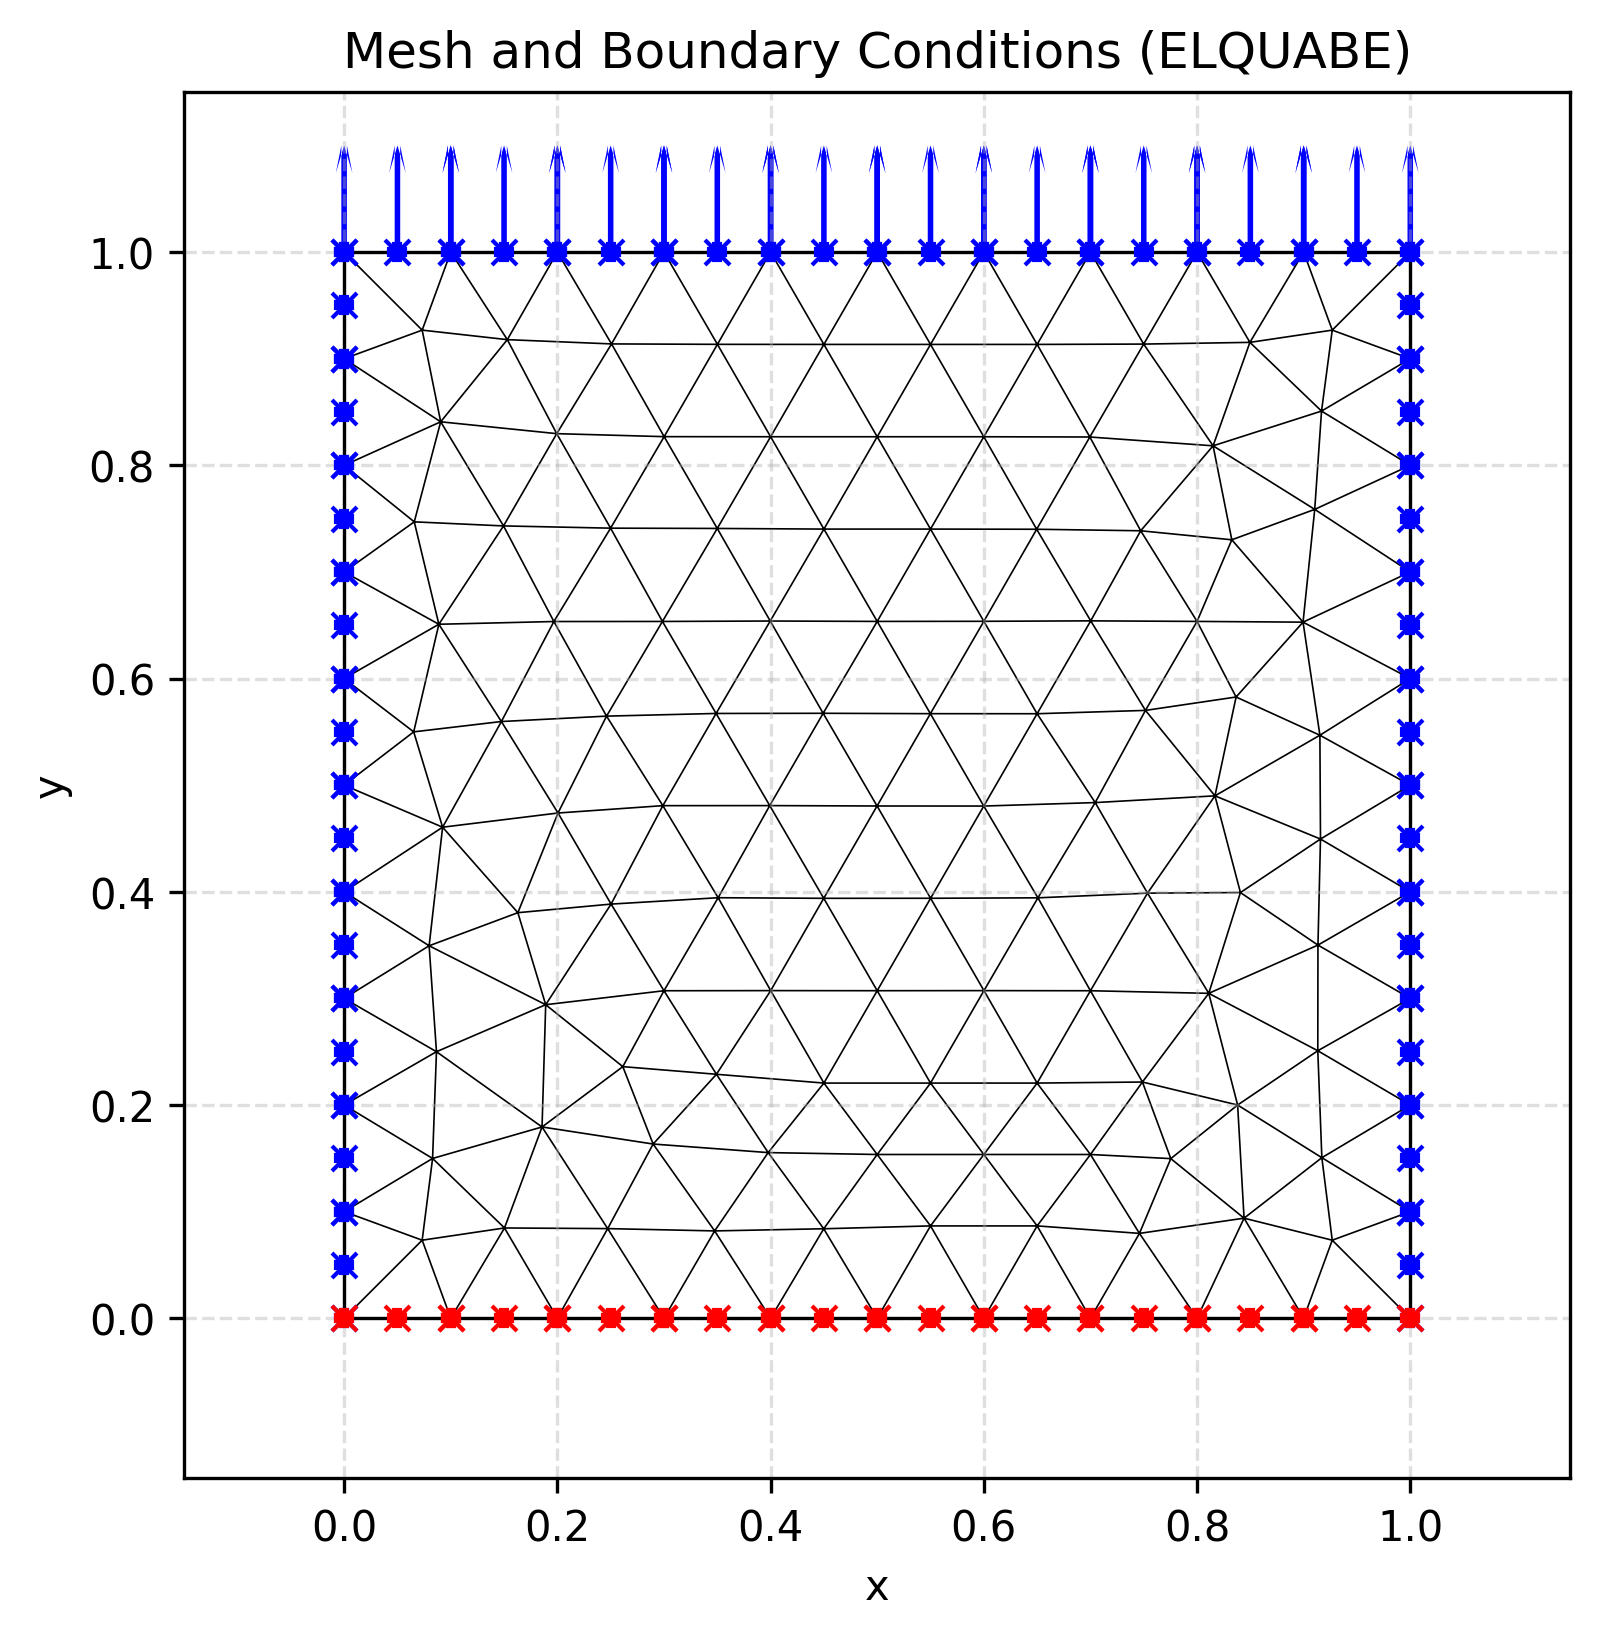

In [54]:
from IPython.display import Image
Image('geometry.png', width=500)

# Run `elquabe_modern.exe`

In [55]:
!./elquabe_modern.exe

In [56]:
ls

assembly_mod.f90      eq12cb.out     __pycache__/
assembly_mod.mod      geometry.png   README.md
assembly_mod.o        input_data.py  resultado_elquabe.vtk
build.bat             io_mod.f90     result_plot.png
data_mod.f90          io_mod.mod     Run_elquabe_on_Colab.ipynb
data_mod.mod          io_mod.o       solver_mod.f90
data_mod.o            main.f90       solver_mod.mod
displacement_map.png  main.o         solver_mod.o
dpbou.dat             Makefile       stbou.dat
dpint.dat             placa.geo      stint.dat
elquabe.for           placa.msh      von_mises_map.png
elquabe_modern.exe*   posproc.py
eq12cb.dat            preproc.py


# Run `posproc.py`

In [57]:
!python posproc.py

ELQUABE 2D ELASTOSTATIC VALIDATION SUMMARY
Relative L2 Error in Vertical Displacement u_y      : 4.5349e-11
Relative L2 Error in von Mises Stress (All Nodes)   : 1.2160e-10
Validation plot saved to 'result_plot.png'.

VTK file 'resultado_elquabe.vtk' saved successfully.
Displacement contour map 'displacement_map.png' saved successfully.
von Mises contour map 'von_mises_map.png' saved successfully.


# Show von Mises equivalent stress

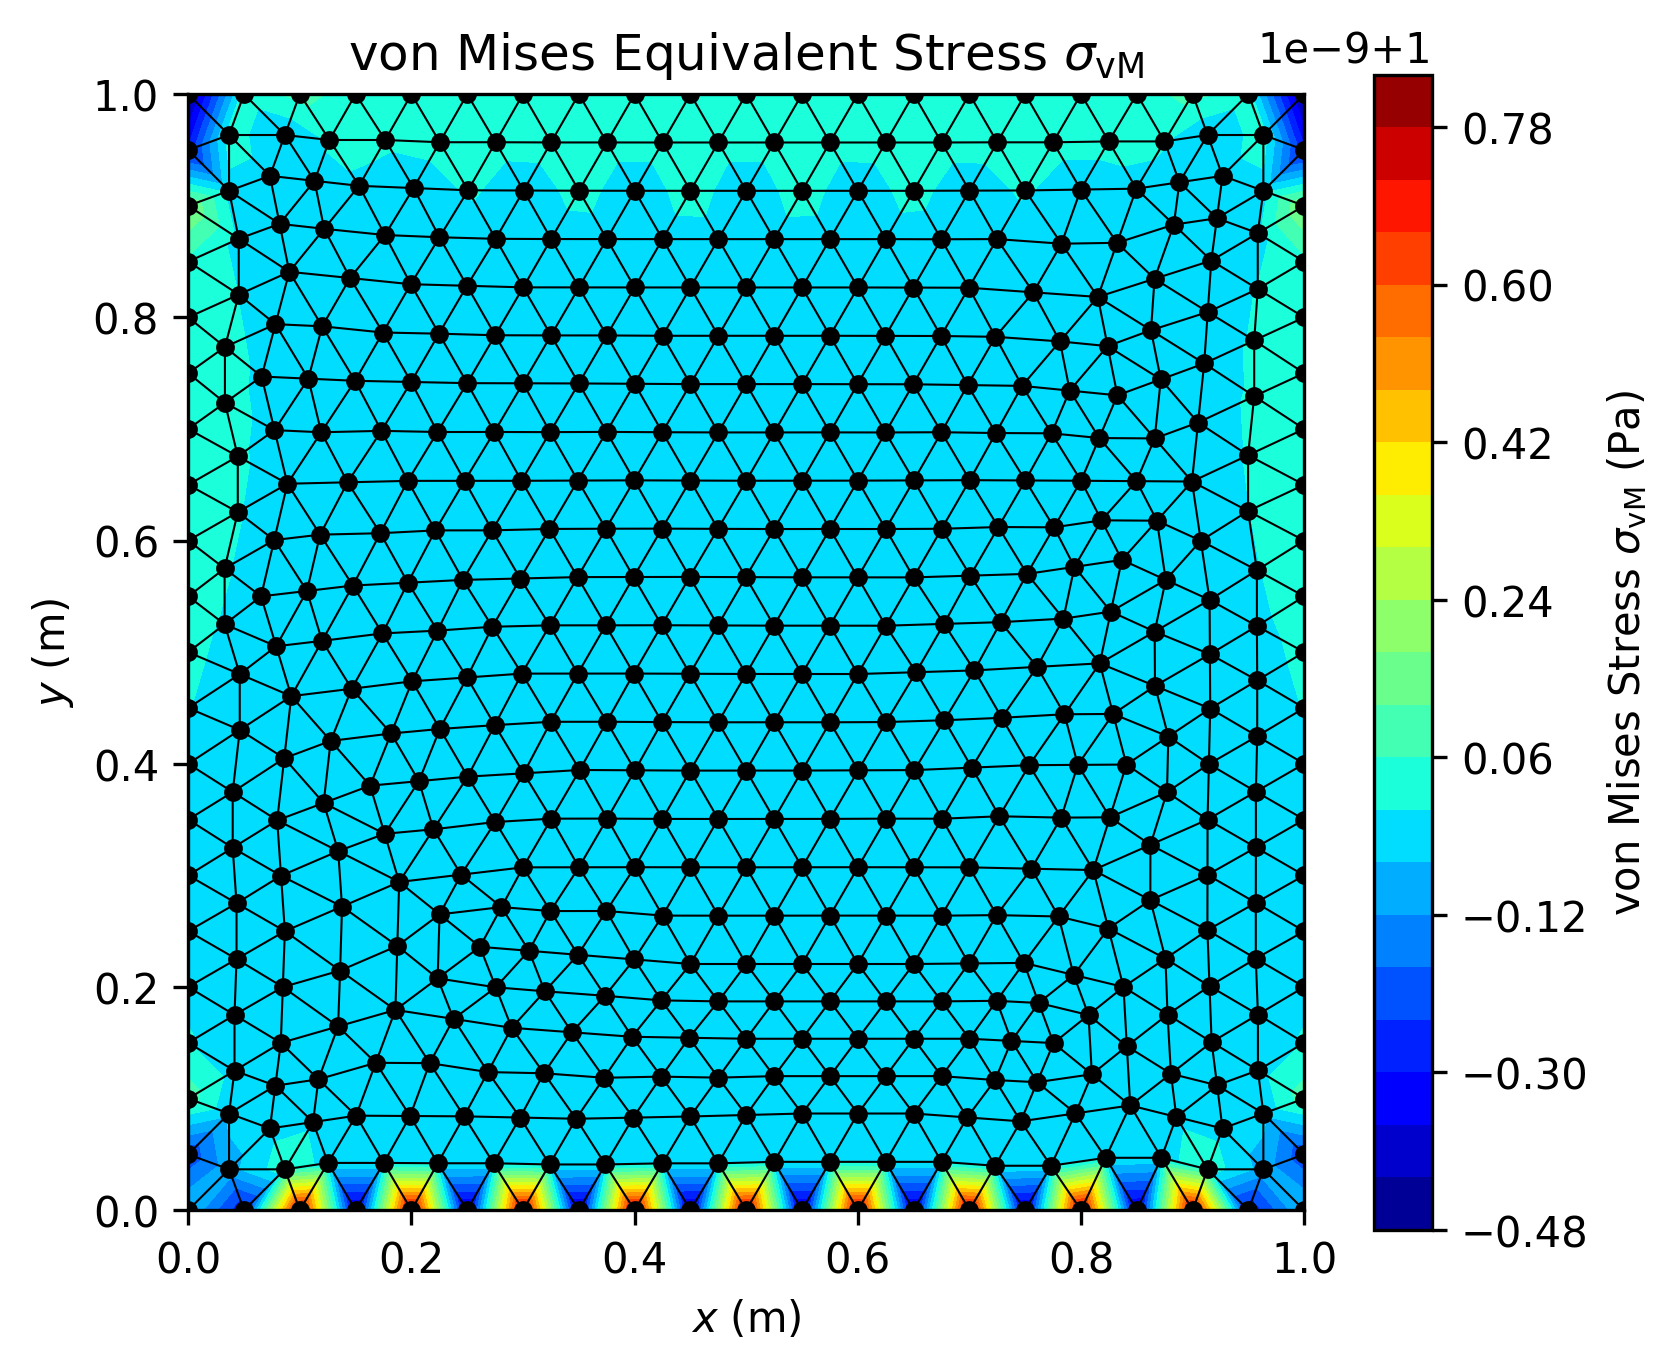

In [58]:
from IPython.display import Image
Image('von_mises_map.png', width=500)